## Ejemplo pequeño con datos reales
Este es un ejemplo para el caso de uso de Esmax, usando datos reales extraídos de los datos compartidos por el cliente.
Se asume una sola planta de distribución (Planta Maipú), y con 5 clientes/estaciones de servicios (Curicó, Molina, Pichilemu, Chimbarongo y Melipilla) asociados a dicha planta. A cada uno de estos clientes se les asocia un pedido o demanda, en metros cúbicos (extraídos de la semana 6 de 2025). También se crea una matriz de distancias, obteniendo aproximados mediante Google Maps, para incluir distancias entre clientes. 

In [2]:
import pandas as pd
import numpy as np
import pyvrp

In [ ]:
data_nodos=pd.read_excel(r'datos_ejemplo_esmax.xlsx')

#5 clientes
#una planta

In [4]:
data_nodos.head(6)

,Nodo,Pedido
0,Planta Maipú,0
1,Curicó,6
2,Molina,20
3,Pichilemu,13
4,Chimbarongo,9
5,Melipilla,10


In [ ]:
df_distancias=pd.read_excel(r'distancias_ejemplo_esmax.xlsx')
#distancias tomadas de google maps, de manera aproximada

In [6]:
df_distancias=df_distancias.iloc[:,1:]

In [7]:
matriz=df_distancias.to_numpy()
print(matriz)

[[  0 170 184 150 135  46]
 [170   0  16  92  35 145]
 [184  16   0 102  49 159]
 [150  92 102   0  97 109]
 [135  35  49  97   0 116]
 [ 46 145 159 109 116   0]]


##### Creando el modelo

Se añaden los datos de la planta, los clientes, y las distancias entre todos los nodos.

In [69]:
modelo=pyvrp.Model()
modelo.add_depot(0,0, name='Planta Maipú')


In [70]:
for i in range(1,len(data_nodos['Nodo'])):
    modelo.add_client(0,0,delivery=int(data_nodos.iloc[i,1]),name=str(data_nodos.iloc[i,0]))


In [71]:
for frm_idx, frm in enumerate(modelo.locations):
    for to_idx, to in enumerate(modelo.locations):
        modelo.add_edge(frm, to, distance=matriz[frm_idx][to_idx])

También se añaden los datos de los vehículos. Estos son datos reales de vehículos extraídos de los datos compartidos desde esmax, siendo todos vehículos asociados a la Planta Maipú. Acá se identifican según el orden en que se añaden al modelo, siendo el primero 0, el segundo 1 y el tercero 2. Esto nos ayudará a comprender la solución final.

In [72]:
modelo.add_vehicle_type(capacity=20, num_available=1, start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_1')
modelo.add_vehicle_type(capacity=35, num_available=1, start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_2')
modelo.add_vehicle_type(capacity=27, num_available=1, start_depot=modelo.locations[0], end_depot=modelo.locations[0], name='camion_3')

##### La solución
Se obtiene la solución del modelo según el algoritmo. Se explica más abajo.


In [ ]:
from pyvrp.stop import MaxRuntime
res = modelo.solve( stop = MaxRuntime (1) , seed = 3)

PyVRP v0.11.3

Solving an instance with:
    1 depot
    5 clients
    3 vehicles (3 vehicle types)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      1s |  32      782      675 |  61      722      663

Search terminated in 1.00s after 894 iterations.
Best-found solution has cost 675.

Solution results
    # routes: 2
     # trips: 2
   # clients: 5
   objective: 675
    distance: 675
    duration: 0
# iterations: 894
    run-time: 1.00 seconds



In [13]:
print(res)

Solution results
    # routes: 2
     # trips: 2
   # clients: 5
   objective: 675
    distance: 675
    duration: 0
# iterations: 894
    run-time: 1.00 seconds

Routes
------
Route #1: 2 1 4
Route #2: 5 3



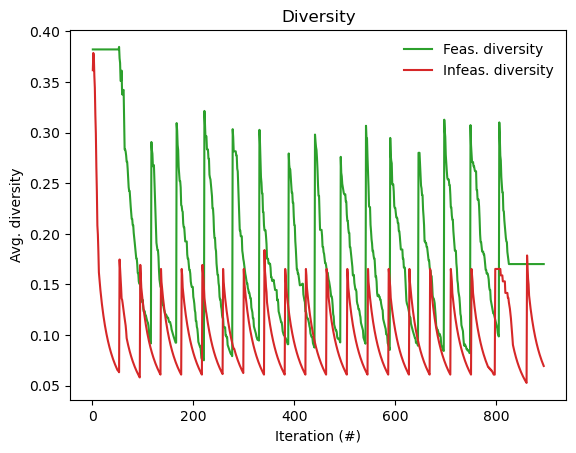

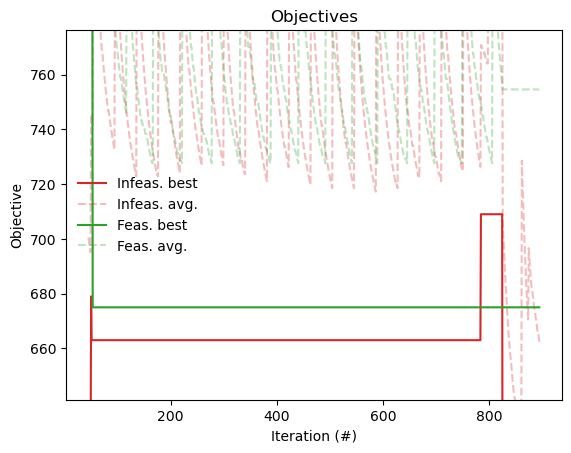

In [14]:
from pyvrp.plotting import plot_diversity, plot_objectives

plot_diversity(res)
plot_objectives(res)

In [58]:
best=res.best
rutas=best.routes()
num_rutas=best.num_routes()

In [64]:
for i in range(0,num_rutas):
    print(f' La ruta recorrida por el vehículo {rutas[i].vehicle_type()} son los clientes {rutas[i]}')

 La ruta recorrida por el vehículo 1 son los clientes 2 1 4
 La ruta recorrida por el vehículo 2 son los clientes 5 3


#### Explicando la solución

En este caso particular existen dos rutas: una por el vehículo 1, es decir, el camion_2, que recorre los clientes 2(Molina),1(Curicó) y 4(Chimbarongo); y la segunda ruta, recorrida por el vehículo 2, es decir, el camion_3, que recorre los clientes, 5(Melipilla) y 3(Pichilemu).